# Tarea 1 – Parte 1: Recolección, limpieza y EDA de noticias peruanas

**Pregunta guía:** ¿Pueden convertir titulares peruanos en un clasificador de noticias?

| Campo | Valor |
|---|---|
| **Fecha de descarga** | 2026-10-18 (hora de Lima, UTC-5) |
| **Opción elegida** | **C – Comparada**: La República + El Comercio (objetivo ≈200 por medio, ≈50 por medio y categoría) |
| **URLs base** | https://larepublica.pe · https://elcomercio.pe |
| **Categorías finales** | `politica`, `economia`, `deportes`, `ciencia_tecnologia` |

**Fuentes consultadas** (todas permitidas por el `robots.txt` de cada medio):

| Medio | RSS oficiales | Sitemaps | Otras rutas HTML |
|---|---|---|---|
| La República | `https://larepublica.pe/rss/{seccion}.xml` y `https://larepublica.pe/rss/home.xml` | `https://larepublica.pe/sitemap/{seccion}.xml` (news) y `https://larepublica.pe/sitemap/web/{seccion}.xml` | Portada de sección `https://larepublica.pe/{seccion}` y enlaces internos de los artículos |
| El Comercio | `https://elcomercio.pe/arc/outboundfeeds/rss/category/{seccion}/?outputType=xml` y feed general `https://elcomercio.pe/arc/outboundfeeds/rss/?outputType=xml` | `https://elcomercio.pe/sitemap/news/{seccion}/?outputType=xml` y `https://elcomercio.pe/sitemap/web/{seccion}/?outputType=xml` | — |

Secciones consultadas: La República → `politica`, `economia`, `deportes`, `ciencia`; El Comercio → `politica`, `economia`, `deporte-total`, `tecnologia`.

## 0. Buenas prácticas y decisiones de extracción

- **robots.txt revisado y aplicado en código.** Ambos medios permiten `/rss/` y `/sitemap/`. La República prohíbe, entre otros, `/archivo/*`, `/*/pag/*` (paginación), `/*/tag/*` y `/buscador*`; El Comercio prohíbe `/buscar/` y `/catalogo/`. Antes de cada solicitud se valida la URL con `urllib.robotparser` más los patrones con comodín que `robotparser` no interpreta.
- **User-Agent descriptivo**, **pausa aleatoria de 1 a 2 s después de cada solicitud** y **máximo 1 reintento** (solo ante error de red, HTTP 429 o 5xx). Se usa un hilo por medio, de modo que nunca hay más de una solicitud simultánea al mismo dominio.
- **Limitación de La República:** sus RSS y sitemaps solo cubren ≈48 horas (p. ej., 6 URLs en el sitemap de economía al momento de la descarga) y el archivo y la paginación están prohibidos. Para llegar al volumen sin infringir el `robots.txt`, se siguen los **enlaces internos que cada artículo publica hacia otras notas de su misma sección** (rutas permitidas), priorizando lo más reciente. Por eso La República abarca un rango de fechas más amplio que El Comercio.
- **El Comercio** publica ≈100 URLs por sección en sus sitemaps web (≈1 semana), suficiente para la cuota.
- **Cada artículo se descarga una sola vez** para obtener `titular` (`og:title`), `bajada` (`meta description`) y `fecha` (`article:published_time` o la fecha en la URL). Eso además **verifica que cada URL funcione (HTTP 200)**.
- **Cuota:** se descargan hasta 55 artículos válidos por medio y categoría (objetivo final ≥ 50 tras la limpieza). Los candidatos que exceden la cuota no se descargan y se reportan.
- **Respaldo crudo** en `datos/raw/`: `robots.txt`, feeds y sitemaps tal como se recibieron (comprimidos `.gz`), la lista de candidatos descubiertos y los metadatos extraídos de cada artículo (`.jsonl`, uno por medio). No se guarda el HTML completo de cada artículo (≈0,3–0,5 MB c/u) para no inflar el repositorio.
- **Reproducibilidad:** si ya existe el respaldo (`datos/raw/metadata_descarga.json`), el notebook se reconstruye desde ahí sin volver a consultar los sitios. Para descargar de nuevo: `FORZAR_DESCARGA = True`.

In [1]:
import gzip, html, json, random, re, time, warnings
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
from datetime import datetime
from pathlib import Path
from urllib import robotparser
from urllib.parse import urljoin, urlsplit, urlunsplit
from zoneinfo import ZoneInfo

import pandas as pd
import plotly.express as px
import plotly.io as pio
import requests
from bs4 import BeautifulSoup, MarkupResemblesLocatorWarning

warnings.filterwarnings("ignore", category=MarkupResemblesLocatorWarning)

# Interactivo en Jupyter/VS Code + copia PNG para que los gráficos se vean en GitHub
pio.renderers.default = "plotly_mimetype+png"
pio.renderers["png"].width, pio.renderers["png"].height = 1000, 560
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 200)

LIMA = ZoneInfo("America/Lima")
DATOS, RAW, GRAFICOS = Path("datos"), Path("datos/raw"), Path("graficos")
for carpeta in (RAW, GRAFICOS):
    carpeta.mkdir(parents=True, exist_ok=True)

FORZAR_DESCARGA = False
USER_AGENT = ("Mozilla/5.0 (compatible; TareaPUCP-Diplomado/1.0; uso academico; "
              "+https://github.com/serugiran96/diplomado_pucp_tareas_melinarozas)")
PAUSA = (1.0, 2.0)          # segundos, aleatoria, después de cada solicitud
MAX_REINTENTOS = 1
TIMEOUT = 20
CUOTA = 55                  # artículos válidos por medio y categoría
CATEGORIAS = ["politica", "economia", "deportes", "ciencia_tecnologia"]
COLUMNAS = ["titular", "bajada", "medio", "seccion_original", "url", "fecha", "etiqueta"]

FUENTES = []  # (medio, tipo, seccion, url)
for s in ["politica", "economia", "deportes", "ciencia"]:
    FUENTES += [("La Republica", "rss", s, f"https://larepublica.pe/rss/{s}.xml"),
                ("La Republica", "sitemap_news", s, f"https://larepublica.pe/sitemap/{s}.xml"),
                ("La Republica", "sitemap_web", s, f"https://larepublica.pe/sitemap/web/{s}.xml"),
                ("La Republica", "portada_seccion", s, f"https://larepublica.pe/{s}")]
FUENTES.append(("La Republica", "rss_general", "home", "https://larepublica.pe/rss/home.xml"))
for s in ["politica", "economia", "deporte-total", "tecnologia"]:
    FUENTES += [("El Comercio", "rss", s, f"https://elcomercio.pe/arc/outboundfeeds/rss/category/{s}/?outputType=xml"),
                ("El Comercio", "sitemap_news", s, f"https://elcomercio.pe/sitemap/news/{s}/?outputType=xml"),
                ("El Comercio", "sitemap_web", s, f"https://elcomercio.pe/sitemap/web/{s}/?outputType=xml")]
FUENTES.append(("El Comercio", "rss_general", "general", "https://elcomercio.pe/arc/outboundfeeds/rss/?outputType=xml"))
HOSTS = {"La Republica": "larepublica.pe", "El Comercio": "elcomercio.pe"}

# Mapeo explícito: (medio, sección principal de la URL) -> categoría final. Lo demás se descarta.
MAPEO_SECCION = {
    ("La Republica", "politica"): "politica",
    ("La Republica", "economia"): "economia",
    ("La Republica", "deportes"): "deportes",
    ("La Republica", "ciencia"): "ciencia_tecnologia",
    ("La Republica", "tecnologia"): "ciencia_tecnologia",
    ("El Comercio", "politica"): "politica",
    ("El Comercio", "elecciones"): "politica",
    ("El Comercio", "economia"): "economia",
    ("El Comercio", "deporte-total"): "deportes",
    ("El Comercio", "tecnologia"): "ciencia_tecnologia",
}
print(f"{len(FUENTES)} fuentes configuradas | cuota {CUOTA} por medio y categoría")

30 fuentes configuradas | cuota 55 por medio y categoría


### 0.1 Funciones auxiliares (HTTP con pausas, robots.txt, parseo)

In [2]:
SESIONES = {medio: requests.Session() for medio in HOSTS}
for sesion in SESIONES.values():
    sesion.headers.update({"User-Agent": USER_AGENT, "Accept-Language": "es-PE,es;q=0.9"})
CONTADOR = Counter()

def obtener(medio, url):
    """GET con pausa aleatoria de 1–2 s tras cada intento y como máximo 1 reintento."""
    for intento in range(1 + MAX_REINTENTOS):
        try:
            r = SESIONES[medio].get(url, timeout=TIMEOUT)
            estado = r.status_code
        except requests.RequestException as e:
            r, estado = None, type(e).__name__
        CONTADOR[medio] += 1
        time.sleep(random.uniform(*PAUSA))
        if r is not None and r.status_code != 429 and r.status_code < 500:
            break
    return r, estado

PROHIBIDOS = [re.compile(p) for p in (r"/pag/", r"/page/", r"/tag/", r"^/archivo/", r"^/archive/",
                                      r"^/buscador", r"^/buscar/", r"^/envivo/", r"^/data(/|$)", r"^/catalogo/")]
ROBOTS = {}

def permitido(url):
    host = urlsplit(url).netloc
    ruta = urlsplit(url).path
    return ROBOTS[host].can_fetch(USER_AGENT, url) and not any(p.search(ruta) for p in PROHIBIDOS)

def normalizar_url(url):
    p = urlsplit(url.strip())
    return urlunsplit(("https", p.netloc.lower(), p.path, "", ""))

def seccion_desde_url(url, medio):
    """Sección tal como figura en la ruta del medio, p. ej. 'tecnologia/redes-sociales'. None si no es artículo."""
    partes = [p for p in urlsplit(url).path.split("/") if p]
    if medio == "La Republica":  # /{seccion}[/{sub}]/AAAA/MM/DD/slug
        for i, p in enumerate(partes):
            if re.fullmatch(r"(19|20)\d{2}", p):
                return "/".join(partes[:i]) or None
        return None
    # El Comercio: /{seccion}[/{sub}]/slug-noticia/
    return "/".join(partes[:-1]) if len(partes) >= 2 and partes[-1].endswith("-noticia") else None

def etiqueta_de(url, medio):
    sec = seccion_desde_url(url, medio)
    return MAPEO_SECCION.get((medio, sec.split("/")[0])) if sec else None

def limpiar_texto(t):
    if not isinstance(t, str) or not t.strip():
        return ""
    t = BeautifulSoup(html.unescape(t), "lxml").get_text(" ")
    t = re.sub(r"\s*\|\s*(La República|La Republica|El Comercio)( Perú)?\s*$", "", t)
    return re.sub(r"\s+", " ", t).strip()

def texto(tag):
    return tag.get_text(" ", strip=True) if tag else ""

def ruta_raw(medio, tipo, seccion, ext):
    return RAW / f"{HOSTS[medio].split('.')[0]}__{tipo}__{seccion}.{ext}.gz"

def parsear_fuente(contenido, medio, tipo, seccion, url_fuente):
    """Devuelve candidatos {url, titular, bajada, fecha} de un RSS, sitemap o portada HTML."""
    items = []
    if tipo == "portada_seccion":
        sopa = BeautifulSoup(contenido, "lxml")
        for a in sopa.find_all("a", href=True):
            u = normalizar_url(urljoin(url_fuente, a["href"]))
            if urlsplit(u).netloc == HOSTS[medio] and seccion_desde_url(u, medio):
                items.append({"url": u, "titular": "", "bajada": "", "fecha": ""})
        return items
    sopa = BeautifulSoup(contenido, "xml")
    for it in sopa.find_all("item"):  # RSS
        items.append({"url": texto(it.find("link")), "titular": texto(it.find("title")),
                      "bajada": texto(it.find("description")), "fecha": texto(it.find("pubDate"))})
    for u in sopa.find_all("url"):   # sitemap
        items.append({"url": texto(u.find("loc")), "titular": texto(u.find("news:title")), "bajada": "",
                      "fecha": texto(u.find("news:publication_date")) or texto(u.find("lastmod"))})
    for it in items:
        it["url"] = normalizar_url(it["url"])
    return [it for it in items if it["url"].startswith("https://")]

def fecha_publicacion_ld(sopa):
    for sc in sopa.find_all("script", type="application/ld+json"):
        m = re.search(r'"datePublished"\s*:\s*"([^"]+)"', sc.string or "")
        if m:
            return m.group(1)
    return ""

def extraer_articulo(medio, url):
    """Descarga un artículo y extrae metadatos + enlaces internos a otros artículos."""
    r, estado = obtener(medio, url)
    rec = {"medio": medio, "url_solicitada": url, "estado_http": estado,
           "descargado_en": datetime.now(LIMA).isoformat(timespec="seconds")}
    if r is None or r.status_code != 200:
        return rec, []
    sopa = BeautifulSoup(r.text, "lxml")
    meta = lambda **kw: ((sopa.find("meta", attrs=kw) or {}).get("content") or "").strip()
    canon = sopa.find("link", rel="canonical")
    rec.update({
        "url_final": normalizar_url(urljoin(r.url, canon["href"]) if canon and canon.get("href") else r.url),
        "og_title": meta(property="og:title"),
        "h1": texto(sopa.h1),
        "meta_description": meta(name="description"),
        "og_description": meta(property="og:description"),
        "published_time": meta(property="article:published_time") or fecha_publicacion_ld(sopa),
        "article_section": meta(property="article:section"),
    })
    enlaces = {normalizar_url(urljoin(r.url, a["href"])) for a in sopa.find_all("a", href=True)}
    enlaces = sorted(e for e in enlaces if urlsplit(e).netloc == HOSTS[medio] and seccion_desde_url(e, medio))
    return rec, enlaces

## 1. Extracción

### 1.1 Descubrimiento de candidatos (RSS, sitemaps y portadas de sección)
Cada respuesta se guarda cruda en `datos/raw/` antes de parsearla. Si el respaldo existe, se lee desde el disco.

In [3]:
META = RAW / "metadata_descarga.json"
MODO_RESPALDO = META.exists() and not FORZAR_DESCARGA
inicio = datetime.now(LIMA).isoformat(timespec="seconds")
print("Modo:", "reconstrucción desde respaldo crudo" if MODO_RESPALDO else "descarga en vivo")

def cargar_robots(medio):
    destino = RAW / f"{HOSTS[medio].split('.')[0]}__robots.txt"
    if not MODO_RESPALDO:
        r, _ = obtener(medio, f"https://{HOSTS[medio]}/robots.txt")
        destino.write_text(r.text, encoding="utf-8")
    rp = robotparser.RobotFileParser()
    rp.parse(destino.read_text(encoding="utf-8").splitlines())
    ROBOTS[HOSTS[medio]] = rp

def descubrir(medio):
    cargar_robots(medio)
    registro, candidatos = [], []
    for m, tipo, seccion, url in FUENTES:
        if m != medio:
            continue
        destino = ruta_raw(medio, tipo, seccion, "html" if tipo == "portada_seccion" else "xml")
        estado = "respaldo" if destino.exists() else "sin respaldo"
        if not MODO_RESPALDO:
            if not permitido(url):
                registro.append({"medio": medio, "tipo": tipo, "seccion": seccion, "url": url, "estado": "bloqueada por robots.txt", "items": 0})
                continue
            r, estado = obtener(medio, url)
            if r is not None and r.status_code == 200:
                destino.write_bytes(gzip.compress(r.content))
        items = parsear_fuente(gzip.decompress(destino.read_bytes()), medio, tipo, seccion, url) if destino.exists() else []
        for it in items:
            it.update({"medio": medio, "fuente": tipo, "seccion_fuente": seccion})
        candidatos += items
        registro.append({"medio": medio, "tipo": tipo, "seccion": seccion, "url": url, "estado": estado, "items": len(items)})
    return registro, candidatos

with ThreadPoolExecutor(max_workers=2) as ex:
    resultados = list(ex.map(descubrir, HOSTS))

fuentes_log = (pd.DataFrame(json.loads(META.read_text(encoding="utf-8"))["fuentes"]) if MODO_RESPALDO
               else pd.DataFrame([f for reg, _ in resultados for f in reg]))
cand_bruto = pd.DataFrame([c for _, cands in resultados for c in cands])
fuentes_log

Modo: reconstrucción desde respaldo crudo


,medio,tipo,seccion,url,estado,items
0,La Republica,rss,politica,https://larepublica.pe/rss/politica.xml,200,24
1,La Republica,sitemap_news,politica,https://larepublica.pe/sitemap/politica.xml,200,24
2,La Republica,sitemap_web,politica,https://larepublica.pe/sitemap/web/politica.xml,200,24
3,La Republica,portada_seccion,politica,https://larepublica.pe/politica,200,31
4,La Republica,rss,economia,https://larepublica.pe/rss/economia.xml,200,6
5,La Republica,sitemap_news,economia,https://larepublica.pe/sitemap/economia.xml,200,6
6,La Republica,sitemap_web,economia,https://larepublica.pe/sitemap/web/economia.xml,200,6
7,La Republica,portada_seccion,economia,https://larepublica.pe/economia,200,25
8,La Republica,rss,deportes,https://larepublica.pe/rss/deportes.xml,200,14
9,La Republica,sitemap_news,deportes,https://larepublica.pe/sitemap/deportes.xml,200,14


In [4]:
# Un candidato por URL (la misma noticia aparece en RSS y sitemaps); se conservan todas sus fuentes
cand_bruto["seccion_original"] = [seccion_desde_url(u, m) for u, m in zip(cand_bruto.url, cand_bruto.medio)]
cand_bruto["etiqueta"] = [etiqueta_de(u, m) for u, m in zip(cand_bruto.url, cand_bruto.medio)]
cand_bruto = cand_bruto[cand_bruto.seccion_original.notna()]   # descarta enlaces que no son artículos

def primero_no_vacio(s):
    s = s[s.astype(str).str.strip() != ""]
    return s.iloc[0] if len(s) else ""

candidatos = (cand_bruto.groupby(["medio", "url"], as_index=False)
              .agg(fuentes=("fuente", lambda s: "+".join(sorted(set(s)))),
                   titular_feed=("titular", primero_no_vacio), bajada_feed=("bajada", primero_no_vacio),
                   fecha_feed=("fecha", primero_no_vacio), seccion_original=("seccion_original", "first"),
                   etiqueta=("etiqueta", "first")))
candidatos.to_csv(RAW / "candidatos_descubiertos.csv", index=False)
DUP_ENTRE_FUENTES = len(cand_bruto) - len(candidatos)

print(f"Ítems leídos en feeds/sitemaps/portadas: {len(cand_bruto)} | URLs únicas: {len(candidatos)} "
      f"| repeticiones entre fuentes: {DUP_ENTRE_FUENTES}")
pd.crosstab(candidatos.medio, candidatos.etiqueta.fillna("(fuera de las 4)"), margins=True, margins_name="Total")

Ítems leídos en feeds/sitemaps/portadas: 1494 | URLs únicas: 682 | repeticiones entre fuentes: 812


etiqueta,(fuera de las 4),ciencia_tecnologia,deportes,economia,politica,Total
medio,,,,,,
El Comercio,91,92,98,99,93,473
La Republica,145,12,14,13,25,209
Total,236,104,112,112,118,682


### 1.2 Descarga de artículos (con cuota y seguimiento de enlaces internos)
Por cada medio y categoría se descargan los candidatos más recientes hasta reunir la cuota de artículos válidos (HTTP 200). Si la cola se agota, se añaden los enlaces internos hacia otras notas de la misma sección encontrados en los artículos ya descargados. Cada registro se escribe en el respaldo `.jsonl` en cuanto se descarga, de modo que una interrupción no pierde lo avanzado.

In [5]:
def fecha_orden(row):
    f = pd.to_datetime(row.fecha_feed, errors="coerce", utc=True, format="mixed") if row.fecha_feed else pd.NaT
    if pd.isna(f):
        m = re.search(r"/(20\d{2})/(\d{2})/(\d{2})/", row.url)
        f = pd.Timestamp(f"{m.group(1)}-{m.group(2)}-{m.group(3)}", tz="UTC") if m else pd.Timestamp("1970-01-01", tz="UTC")
    return f

candidatos["fecha_orden"] = candidatos.apply(fecha_orden, axis=1)

def leer_jsonl(ruta):
    return [json.loads(l) for l in ruta.read_text(encoding="utf-8").splitlines() if l.strip()] if ruta.exists() else []

def rastrear(medio):
    ruta = RAW / f"articulos_{HOSTS[medio].split('.')[0]}.jsonl"
    registros = leer_jsonl(ruta)
    if MODO_RESPALDO:
        return registros, []
    validos = Counter(etiqueta_de(r["url_final"], medio) for r in registros if r.get("estado_http") == 200)
    vistos = {r["url_solicitada"] for r in registros}
    sub = candidatos[(candidatos.medio == medio) & candidatos.etiqueta.notna()].sort_values("fecha_orden", ascending=False)
    colas = {cat: list(sub[sub.etiqueta == cat].url) for cat in CATEGORIAS}
    en_cola = set(sub.url)
    internos = []
    with ruta.open("a", encoding="utf-8") as f:
        for cat in CATEGORIAS:
            while validos[cat] < CUOTA and colas[cat]:
                url = colas[cat].pop(0)
                if url in vistos:
                    continue
                vistos.add(url)
                if not permitido(url):
                    rec, enlaces = {"medio": medio, "url_solicitada": url, "estado_http": "bloqueada por robots.txt"}, []
                else:
                    rec, enlaces = extraer_articulo(medio, url)
                rec["categoria_cola"] = cat
                f.write(json.dumps(rec, ensure_ascii=False) + "\n"); f.flush()
                registros.append(rec)
                if rec.get("estado_http") == 200:
                    validos[etiqueta_de(rec["url_final"], medio)] += 1
                for e in enlaces:
                    cat_e = etiqueta_de(e, medio)
                    if cat_e and e not in en_cola and e not in vistos:
                        en_cola.add(e)
                        colas[cat_e].append(e)
                        internos.append({"medio": medio, "url": e, "etiqueta": cat_e, "encontrado_en": url})
            print(f"{medio:12s} | {cat:18s} | válidos: {validos[cat]:3d} | solicitudes acumuladas: {CONTADOR[medio]}")
    return registros, internos

t0 = time.time()
with ThreadPoolExecutor(max_workers=2) as ex:
    salida = list(ex.map(rastrear, HOSTS))
registros = [r for regs, _ in salida for r in regs]
enlaces_internos = pd.DataFrame([e for _, ints in salida for e in ints])

if not MODO_RESPALDO:
    if len(enlaces_internos):
        enlaces_internos.to_csv(RAW / "enlaces_internos_descubiertos.csv", index=False)
    META.write_text(json.dumps({
        "inicio": inicio, "fin": datetime.now(LIMA).isoformat(timespec="seconds"),
        "user_agent": USER_AGENT, "pausa_segundos": PAUSA, "max_reintentos": MAX_REINTENTOS, "cuota": CUOTA,
        "solicitudes_http": dict(CONTADOR), "fuentes": fuentes_log.to_dict("records"),
    }, ensure_ascii=False, indent=2), encoding="utf-8")

meta = json.loads(META.read_text(encoding="utf-8"))
print(f"\nDescarga realizada entre {meta['inicio']} y {meta['fin']} | solicitudes HTTP: {meta['solicitudes_http']}")
print(f"Artículos registrados en el respaldo: {len(registros)} | tiempo de esta ejecución: {time.time() - t0:.0f} s")


Descarga realizada entre 2026-10-18T23:31:30-05:00 y 2026-10-18T23:42:38-05:00 | solicitudes HTTP: {'El Comercio': 234, 'La Republica': 239}
Artículos registrados en el respaldo: 441 | tiempo de esta ejecución: 0 s


## 2. Limpieza y normalización

### 2.1 Construcción de las columnas
- `titular`: `og:title` del artículo (si falta, `<h1>` o el título del feed).
- `bajada`: `meta description` (si falta, `og:description` o la descripción del RSS).
- `seccion_original`: sección tal como aparece en la ruta de la URL del medio (p. ej., `deporte-total/futbol-peruano`).
- `fecha`: `article:published_time` o `datePublished` (El Comercio) o la fecha incluida en la URL (La República), en formato `AAAA-MM-DD`, hora de Lima.

In [6]:
art = pd.DataFrame(registros)
art["estado_http"] = art["estado_http"].astype(str)
art = art.merge(candidatos[["medio", "url", "titular_feed", "bajada_feed", "fecha_feed", "fuentes"]],
                left_on=["medio", "url_solicitada"], right_on=["medio", "url"], how="left").drop(columns="url")
art["fuentes"] = art["fuentes"].fillna("enlace_interno")

def elegir(*cols):
    out = pd.Series("", index=art.index)
    for c in cols:
        v = art[c].fillna("").map(limpiar_texto) if c in art else ""
        out = out.where(out != "", v)
    return out

def fecha_final(row):
    for v in (row.get("published_time"), row.get("fecha_feed")):
        f = pd.to_datetime(v, errors="coerce", utc=True, format="mixed") if isinstance(v, str) and v else pd.NaT
        if pd.notna(f):
            return f.tz_convert(LIMA).strftime("%Y-%m-%d")
    m = re.search(r"/(20\d{2})/(\d{2})/(\d{2})/", str(row.get("url_final") or row.url_solicitada))
    return f"{m.group(1)}-{m.group(2)}-{m.group(3)}" if m else ""

art["titular"] = elegir("og_title", "h1", "titular_feed")
art["bajada"] = elegir("meta_description", "og_description", "bajada_feed")
art["url"] = art["url_final"].fillna(art["url_solicitada"])
art["seccion_original"] = [seccion_desde_url(u, m) for u, m in zip(art.url, art.medio)]
art["etiqueta"] = [etiqueta_de(u, m) for u, m in zip(art.url, art.medio)]
art["fecha"] = art.apply(fecha_final, axis=1)
print("Registros de artículos antes de limpiar:", art.shape)
art[["medio", "estado_http", "fuentes", "seccion_original", "etiqueta", "titular"]].head()

Registros de artículos antes de limpiar: (441, 22)


,medio,estado_http,fuentes,seccion_original,etiqueta,titular
0,La Republica,200,portada_seccion+rss+rss_general+sitemap_news+sitemap_web,politica,politica,Diputado de Obras Arturo Eusebio es cuestionado por presunto plagio en su tesis de maestría
1,La Republica,200,portada_seccion+rss+rss_general+sitemap_news+sitemap_web,politica,politica,"Jorge Nieto a Álvaro Vargas Llosa: ""Su rol de comentarista político ya acabó, debería comportarse como un ..."
2,La Republica,200,portada_seccion+rss+rss_general+sitemap_news+sitemap_web,politica,politica,Comisión de Ética recomienda suspender por 120 días al diputado Julián Pérez Mallqui
3,La Republica,200,portada_seccion+rss+rss_general+sitemap_news+sitemap_web,politica,politica,Keiko Fujimori coordina con Delcy Rodríguez la expulsión de venezolanos indocumentados
4,La Republica,200,portada_seccion+rss+rss_general+sitemap_news+sitemap_web,politica,politica,Detención de seis policías por presunto robo reaviva debate sobre reforma de la PNP


### 2.2 Tabla de equivalencias `seccion_original` → `etiqueta`
La regla se aplica sobre la **sección principal** de la URL (primer segmento). La tabla muestra cada `seccion_original` observada en los candidatos y en los artículos descargados, con su categoría final; las que no corresponden a ninguna de las 4 categorías se marcan como `DESCARTADA`.

In [7]:
regla = pd.DataFrame([{"medio": m, "seccion_principal": s, "etiqueta": e} for (m, s), e in MAPEO_SECCION.items()])
print("Regla de mapeo (sección principal → categoría):")
display(regla)

observadas = pd.concat([candidatos[["medio", "seccion_original"]], art[["medio", "seccion_original"]]]).dropna()
tabla_mapeo = (observadas.drop_duplicates()
               .assign(seccion_principal=lambda d: d.seccion_original.str.split("/").str[0],
                       etiqueta=lambda d: [MAPEO_SECCION.get((m, s), "DESCARTADA") for m, s in zip(d.medio, d.seccion_principal)])
               .merge(art[art.estado_http == "200"].groupby(["medio", "seccion_original"]).size().rename("articulos_descargados").reset_index(),
                      how="left", on=["medio", "seccion_original"])
               .fillna({"articulos_descargados": 0}).astype({"articulos_descargados": int})
               .sort_values(["medio", "etiqueta", "seccion_original"]).reset_index(drop=True))
tabla_mapeo.to_csv(DATOS / "raw" / "tabla_mapeo_secciones.csv", index=False)
print(f"Secciones originales observadas: {len(tabla_mapeo)} "
      f"({(tabla_mapeo.etiqueta != 'DESCARTADA').sum()} mapeadas, {(tabla_mapeo.etiqueta == 'DESCARTADA').sum()} descartadas)")
with pd.option_context("display.max_rows", 200):
    display(tabla_mapeo)

Regla de mapeo (sección principal → categoría):


,medio,seccion_principal,etiqueta
0,La Republica,politica,politica
1,La Republica,economia,economia
2,La Republica,deportes,deportes
3,La Republica,ciencia,ciencia_tecnologia
4,La Republica,tecnologia,ciencia_tecnologia
5,El Comercio,politica,politica
6,El Comercio,elecciones,politica
7,El Comercio,economia,economia
8,El Comercio,deporte-total,deportes
9,El Comercio,tecnologia,ciencia_tecnologia


Secciones originales observadas: 90 (41 mapeadas, 49 descartadas)


,medio,seccion_original,seccion_principal,etiqueta,articulos_descargados
0,El Comercio,bbc-news-mundo,bbc-news-mundo,DESCARTADA,0
1,El Comercio,ecdata,ecdata,DESCARTADA,0
2,El Comercio,eldominical/ciencia,eldominical,DESCARTADA,0
3,El Comercio,lima,lima,DESCARTADA,0
4,El Comercio,lima/seguridad,lima,DESCARTADA,0
5,El Comercio,lima/sucesos,lima,DESCARTADA,0
6,El Comercio,mag/respuestas,mag,DESCARTADA,0
7,El Comercio,mag/respuestas/mx,mag,DESCARTADA,0
8,El Comercio,mag/respuestas/us,mag,DESCARTADA,0
9,El Comercio,mag/usa/california,mag,DESCARTADA,0


### 2.3 Limpieza: URLs no funcionales, titulares vacíos, duplicados y secciones fuera de alcance

In [8]:
descartes = []
def descartar(df, mascara, motivo):
    for medio, n in df[mascara].groupby("medio").size().items():
        descartes.append({"etapa": "limpieza", "motivo": motivo, "medio": medio, "n": int(n)})
    return df[~mascara].copy()

df = art.copy()
df = descartar(df, df.estado_http != "200", "URL no funcional o bloqueada (sin HTTP 200)")
df = descartar(df, df.titular.str.strip() == "", "Titular vacío")
df = descartar(df, df.duplicated(subset="url", keep="first"), "Duplicado por URL (misma URL canónica)")
df = descartar(df, df.etiqueta.isna(), "Sección final fuera de las 4 categorías (redirección a otra sección)")
df = descartar(df, df.duplicated(subset=["medio", "titular"], keep="first"), "Titular duplicado en el mismo medio (otra URL)")

# Descartes y exclusiones previos a la descarga (nivel candidato)
fuera = candidatos[candidatos.etiqueta.isna()]
for medio, n in fuera.groupby("medio").size().items():
    descartes.append({"etapa": "descubrimiento", "motivo": "Sección fuera de las 4 categorías (no se descarga)", "medio": medio, "n": int(n)})
for medio, n in cand_bruto.groupby("medio").size().sub(candidatos.groupby("medio").size()).items():
    descartes.append({"etapa": "descubrimiento", "motivo": "Duplicado por URL entre fuentes (RSS/sitemap/portada)", "medio": medio, "n": int(n)})
solicitadas = set(art.url_solicitada)
excedente = candidatos[candidatos.etiqueta.notna() & ~candidatos.url.isin(solicitadas)]
for medio, n in excedente.groupby("medio").size().items():
    descartes.append({"etapa": "descubrimiento", "motivo": "No descargado: cuota de la categoría ya cubierta (excedente)", "medio": medio, "n": int(n)})

reporte = (pd.DataFrame(descartes).pivot_table(index=["etapa", "motivo"], columns="medio", values="n", aggfunc="sum", fill_value=0))
reporte["Total"] = reporte.sum(axis=1)
print(f"Artículos descargados: {len(art)} → filas finales: {len(df)} | descartados en limpieza: {len(art) - len(df)}")
reporte

Artículos descargados: 441 → filas finales: 440 | descartados en limpieza: 1


medio                                                                        El Comercio  La Republica  Total
etapa          motivo                                                                                        
descubrimiento Duplicado por URL entre fuentes (RSS/sitemap/portada)                 554           258    812
               No descargado: cuota de la categoría ya cubierta (excedente)          162             0    162
               Sección fuera de las 4 categorías (no se descarga)                     91           145    236
limpieza       URL no funcional o bloqueada (sin HTTP 200)                             0             1      1

In [9]:
# Normalización final y controles de calidad
df = df[COLUMNAS].reset_index(drop=True)
assert df.titular.str.len().gt(0).all() and df.url.is_unique and df.etiqueta.isin(CATEGORIAS).all()
print("Bajadas vacías (se conservan; el titular es el campo principal):", (df.bajada == "").sum())
print("Fechas vacías:", (df.fecha == "").sum(), "| rango de fechas:", df.fecha.min(), "→", df.fecha.max())
print("Todas las URLs finales respondieron HTTP 200 al momento de la descarga:", len(df), "de", len(df))
pd.crosstab(df.etiqueta, df.medio, margins=True, margins_name="Total")

Bajadas vacías (se conservan; el titular es el campo principal): 0
Fechas vacías: 0 | rango de fechas: 2019-08-04 → 2026-10-18
Todas las URLs finales respondieron HTTP 200 al momento de la descarga: 440 de 440


medio,El Comercio,La Republica,Total
etiqueta,,,
ciencia_tecnologia,55,55,110
deportes,55,55,110
economia,55,55,110
politica,55,55,110
Total,220,220,440


**Resultado de la limpieza (descarga del 18/10/2026):**

- **Descubrimiento:** se leyeron 1 494 ítems en feeds, sitemaps y portadas, que corresponden a 682 URLs únicas. Las 812 repeticiones entre fuentes se unificaron por URL.
- **Fuera de alcance:** 236 candidatos eran de secciones fuera de las 4 categorías (por ejemplo `mundo`, `sociedad`, `espectaculos`, `lima`, `mag`) y se descartaron sin descargarlos. No se creó una quinta categoría.
- **Excedente:** 162 candidatos de El Comercio no se descargaron porque la cuota de su categoría ya estaba cubierta.
- **Limpieza:** de 441 artículos descargados se descartó 1 porque no respondió HTTP 200. No hubo titulares vacíos ni duplicados por URL o por titular.
- **Dataset final:** **440 noticias reales, 55 por medio y categoría**, sin bajadas ni fechas vacías.

## 3. Análisis exploratorio (Plotly Express)
Los títulos de cada gráfico se calculan a partir de los datos para expresar la conclusión. Cada figura se muestra interactiva y además se guarda como PNG en `graficos/`.

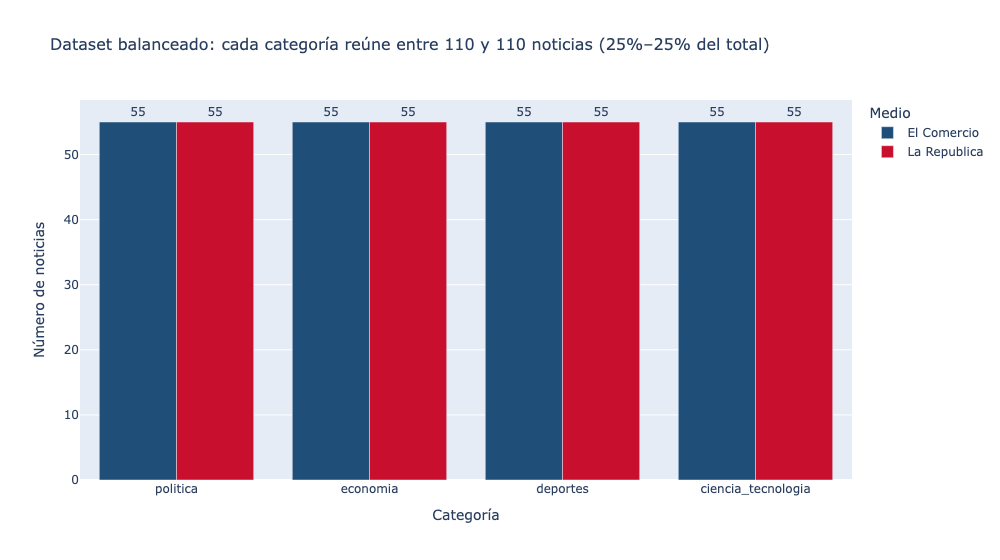

In [10]:
NOMBRE = {"politica": "Política", "economia": "Economía", "deportes": "Deportes", "ciencia_tecnologia": "Ciencia y tecnología"}
COLORES = {"La Republica": "#C8102E", "El Comercio": "#1F4E79"}

conteo = df.groupby(["etiqueta", "medio"]).size().reset_index(name="noticias")
por_cat = df.etiqueta.value_counts()
cat_min, cat_max = por_cat.idxmin(), por_cat.idxmax()
if por_cat.max() / por_cat.min() <= 1.15:
    titulo1 = (f"Dataset balanceado: cada categoría reúne entre {por_cat.min()} y {por_cat.max()} noticias "
               f"({por_cat.min()/len(df):.0%}–{por_cat.max()/len(df):.0%} del total)")
else:
    titulo1 = (f"{NOMBRE[cat_max]} domina con {por_cat.max()} noticias; {NOMBRE[cat_min]} es la más escasa "
               f"({por_cat.min()}, {por_cat.min()/len(df):.0%} del total)")
fig1 = px.bar(conteo, x="etiqueta", y="noticias", color="medio", barmode="group", text="noticias",
              category_orders={"etiqueta": CATEGORIAS}, color_discrete_map=COLORES,
              labels={"etiqueta": "Categoría", "noticias": "Número de noticias", "medio": "Medio"},
              title=titulo1)
fig1.update_traces(textposition="outside")
fig1.update_layout(title_font_size=16, legend_title_text="Medio")
fig1.write_image(GRAFICOS / "01_noticias_por_categoria.png", width=1000, height=560, scale=2)
fig1.show()

**Lectura:** el balance perfecto (55 por celda) viene de la **cuota de muestreo**, no de la distribución natural de los medios. En los feeds y sitemaps de La República solo había entre 12 y 25 candidatos por categoría; el resto se obtuvo siguiendo enlaces internos de la misma sección. El balance favorece el entrenamiento: con F1 macro ninguna clase domina.

Resorting to unclean kill browser.


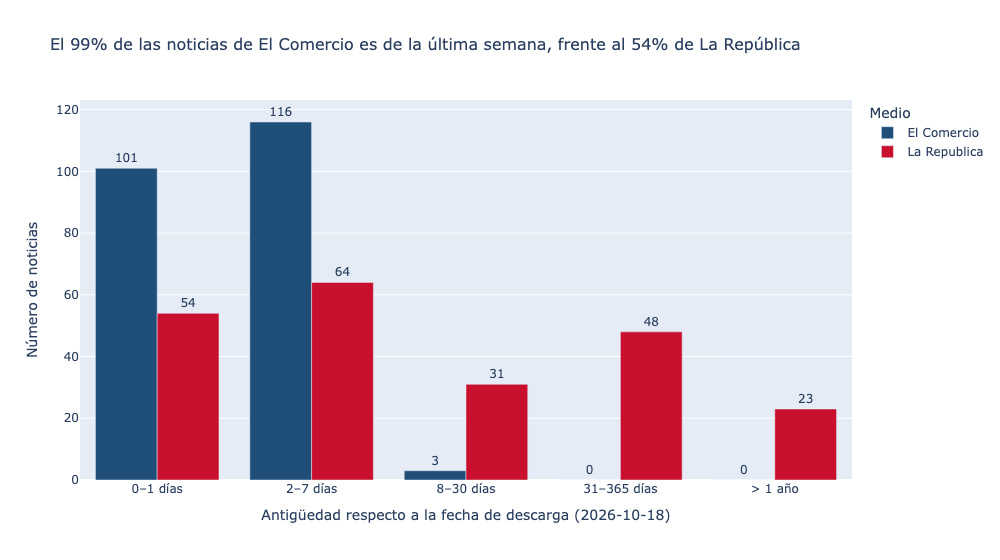

,min,median,max
medio,,,
El Comercio,2026-10-09,2026-10-16,2026-10-18
La Republica,2019-08-04,2026-10-12,2026-10-18


In [11]:
ref = pd.Timestamp(meta["inicio"][:10])
dias = (ref - pd.to_datetime(df.fecha)).dt.days
df_f = df.assign(rango=pd.cut(dias, bins=[-10**5, 1, 7, 30, 365, 10**5],
                              labels=["0–1 días", "2–7 días", "8–30 días", "31–365 días", "> 1 año"]))
rangos = df_f.groupby(["medio", "rango"], observed=False).size().reset_index(name="noticias")
rangos["porcentaje"] = rangos.noticias / rangos.groupby("medio").noticias.transform("sum")
semana = df_f[dias <= 7].groupby("medio").size() / df_f.groupby("medio").size()
titulo2 = (f"El {semana.get('El Comercio', 0):.0%} de las noticias de El Comercio es de la última semana, "
           f"frente al {semana.get('La Republica', 0):.0%} de La República")
fig2 = px.bar(rangos, x="rango", y="noticias", color="medio", barmode="group", text="noticias",
              color_discrete_map=COLORES, hover_data={"porcentaje": ":.1%"},
              labels={"rango": f"Antigüedad respecto a la fecha de descarga ({ref.date()})", "noticias": "Número de noticias", "medio": "Medio"},
              title=titulo2)
fig2.update_traces(textposition="outside")
fig2.update_layout(title_font_size=16)
fig2.write_image(GRAFICOS / "02_noticias_por_medio_y_fecha.png", width=1000, height=560, scale=2)
fig2.show()
df.assign(fecha=pd.to_datetime(df.fecha)).groupby("medio").fecha.agg(["min", "median", "max"])

**Lectura:** El Comercio aporta un corte casi sincrónico (del 9 al 18 de octubre de 2026, mediana el 16). La República se extiende hacia atrás (mediana el 12 de octubre y algunas notas desde 2019), porque sus artículos enlazan notas antiguas de la misma sección. Al comparar medios hay que considerar este desfase: los temas de actualidad (por ejemplo, el debate de facultades en el Congreso) están sobrerrepresentados en El Comercio.

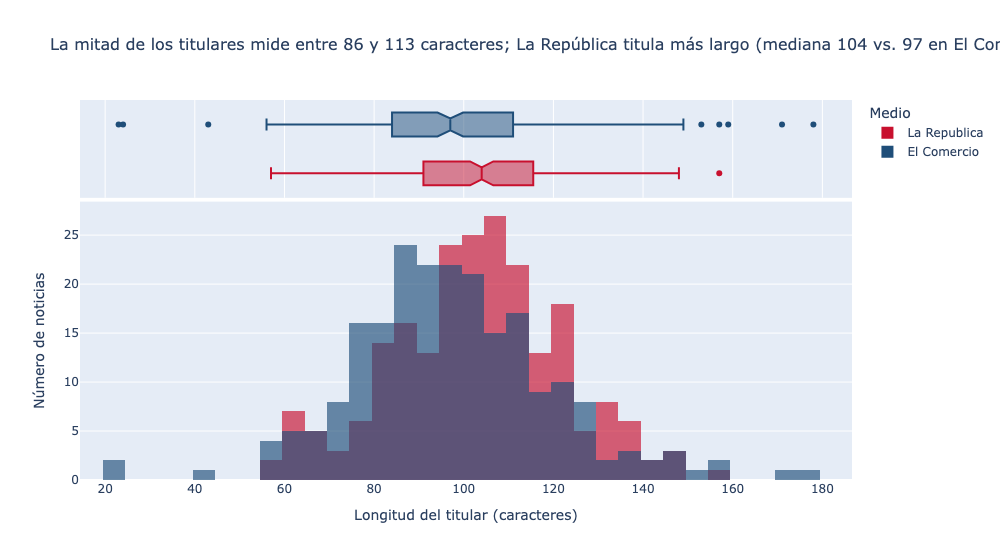

,count,mean,std,min,25%,50%,75%,max
medio,,,,,,,,
El Comercio,220.0,97.7,22.7,23.0,84.0,97.0,111.0,178.0
La Republica,220.0,102.9,19.3,57.0,91.0,104.0,115.2,157.0


In [12]:
df_l = df.assign(largo=df.titular.str.len())
med = df_l.groupby("medio").largo.median()
q1, q3 = df_l.largo.quantile([0.25, 0.75]).round().astype(int)
mas_largo = med.idxmax(); mas_corto = med.idxmin()
nombre_medio = {"La Republica": "La República", "El Comercio": "El Comercio"}
titulo3 = (f"La mitad de los titulares mide entre {q1} y {q3} caracteres; {nombre_medio[mas_largo]} titula más largo "
           f"(mediana {med.max():.0f} vs. {med.min():.0f} en {nombre_medio[mas_corto]})")
fig3 = px.histogram(df_l, x="largo", color="medio", nbins=40, barmode="overlay", opacity=0.65, marginal="box",
                    color_discrete_map=COLORES,
                    labels={"largo": "Longitud del titular (caracteres)", "count": "Noticias", "medio": "Medio"},
                    title=titulo3)
fig3.update_layout(title_font_size=16, yaxis_title="Número de noticias")
fig3.write_image(GRAFICOS / "03_longitud_titulares.png", width=1000, height=560, scale=2)
fig3.show()
df_l.groupby("medio").largo.describe().round(1)

**Lectura:** La República titula algo más largo (mediana de 104 caracteres frente a 97). El Comercio muestra más dispersión: tiene los titulares más cortos (columnas de opinión de economía, desde 23 caracteres) y los más largos (citas textuales en deportes y política, hasta 178).

## 4. Validación: titulares más largos y más cortos

In [13]:
cols = ["largo", "medio", "etiqueta", "titular", "url"]
print("5 titulares MÁS LARGOS")
display(df_l.nlargest(5, "largo")[cols])
print("5 titulares MÁS CORTOS")
display(df_l.nsmallest(5, "largo")[cols])
print(f"Rango del histograma: {df_l.largo.min()} – {df_l.largo.max()} caracteres "
      f"(coincide con el mínimo y máximo de las tablas: {df_l.nsmallest(1, 'largo').largo.iloc[0]} y {df_l.nlargest(1, 'largo').largo.iloc[0]})")

5 titulares MÁS LARGOS


,largo,medio,etiqueta,titular,url
359,178,El Comercio,deportes,"“El jugador peruano tiene un déficit grande en nutrición y táctica que resuelve a los 20 años, eso en Arge...",https://elcomercio.pe/deporte-total/futbol-peruano/universitario-el-jugador-peruano-tiene-un-deficit-grand...
360,171,El Comercio,deportes,El furioso “Que se dedique a administrar” de Guede a Franco Velazco y un Quevedo que reconquistó a Comando...,https://elcomercio.pe/deporte-total/futbol-peruano/alianza-lima-el-furioso-que-se-dedique-a-administrar-de...
270,159,El Comercio,politica,Ernesto Álvarez sobre lucha contra la extorsión: “Este delito no se combate con presencia policial en la c...,https://elcomercio.pe/politica/gobierno/ernesto-alvarez-sobre-lucha-contra-la-extorsion-este-delito-no-se-...
200,157,La Republica,ciencia_tecnologia,China marca un nuevo récord con un aerogenerador transportable a 4.000 m: un dirigible de helio del tamaño...,https://larepublica.pe/ciencia/2026/08/28/china-marca-un-nuevo-record-con-un-aerogenerador-transportable-a...
247,157,El Comercio,politica,Flavio Figallo del Partido del Buen Gobierno: “No queremos obstruir ni evitar que se gobierne. Somos un pa...,https://elcomercio.pe/politica/congreso/flavio-figallo-del-partido-del-buen-gobierno-no-queremos-obstruir-...


5 titulares MÁS CORTOS


,largo,medio,etiqueta,titular,url
282,23,El Comercio,economia,AlaCena no tiene precio,https://elcomercio.pe/economia/opinion/alacena-no-tiene-precio-noticia/
302,24,El Comercio,economia,IA y Sandbox regulatorio,https://elcomercio.pe/economia/opinion/ia-y-sandbox-regulatorio-por-gonzalo-ruiz-macroconsult-opinion-noti...
285,43,El Comercio,economia,Premio Nobel de Economía: la macro es micro,https://elcomercio.pe/economia/opinion/premio-nobel-de-economia-la-macro-es-micro-noticia/
344,56,El Comercio,deportes,CD Moquegua venció a FC Cajamarca por el Torneo Clausura,https://elcomercio.pe/deporte-total/futbol-peruano/fc-cajamarca-vs-cd-moquegua-en-vivo-hora-canal-tv-y-don...
136,57,La Republica,deportes,¿Cuándo inicia la Liga Peruana de Vóley Femenina 2026-27?,https://larepublica.pe/deportes/2026/10/13/cuando-inicia-la-liga-peruana-de-voley-femenino-202627-423826


Rango del histograma: 23 – 178 caracteres (coincide con el mínimo y máximo de las tablas: 23 y 178)


**Coherencia con el histograma:** los extremos de las tablas (23 y 178 caracteres) coinciden con el rango del histograma.

- **Más cortos:** columnas de opinión de El Comercio Economía ("AlaCena no tiene precio", "IA y Sandbox regulatorio"). Son titulares con poca señal temática, así que se espera que el clasificador falle en ese tipo de casos.
- **Más largos:** citas textuales entre comillas en deportes y política.

No se detectaron titulares truncados ni basura de HTML.

## 5. Exportación de `datos/noticias.csv`

In [14]:
df.to_csv(DATOS / "noticias.csv", index=False, encoding="utf-8")
control = pd.read_csv(DATOS / "noticias.csv")
assert list(control.columns) == COLUMNAS and len(control) == len(df)
print("df.shape:", df.shape)
df.head()

df.shape: (440, 7)


,titular,bajada,medio,seccion_original,url,fecha,etiqueta
0,Diputado de Obras Arturo Eusebio es cuestionado por presunto plagio en su tesis de maestría,"De acuerdo con un reportaje de Cuarto Poder, las coincidencias identificadas incluyen pasajes de tesis uni...",La Republica,politica,https://larepublica.pe/politica/2026/10/18/diputado-de-obras-arturo-eusebio-es-cuestionado-por-presunto-pl...,2026-10-18,politica
1,"Jorge Nieto a Álvaro Vargas Llosa: ""Su rol de comentarista político ya acabó, debería comportarse como un ...",El líder de Buen Gobierno resaltó que su partido no está obstaculizando el pedido de facultades legislativ...,La Republica,politica,https://larepublica.pe/politica/2026/10/18/jorge-nieto-a-alvaro-vargas-llosa-su-rol-de-comentarista-politi...,2026-10-18,politica
2,Comisión de Ética recomienda suspender por 120 días al diputado Julián Pérez Mallqui,"Según el documento, la conducta atribuida al diputado afectó la imagen institucional del Congreso y contra...",La Republica,politica,https://larepublica.pe/politica/2026/10/18/comision-de-etica-recomienda-suspender-por-120-dias-al-diputado...,2026-10-18,politica
3,Keiko Fujimori coordina con Delcy Rodríguez la expulsión de venezolanos indocumentados,"La mandataria informó que su Gobierno iniciará el apoyo al programa Vuelta a la Patria, iniciativa venezol...",La Republica,politica,https://larepublica.pe/politica/2026/10/18/keiko-fujimori-coordina-con-delcy-rodriguez-la-expulsion-de-ven...,2026-10-18,politica
4,Detención de seis policías por presunto robo reaviva debate sobre reforma de la PNP,La situación ha llevado a que la desconfianza en la PNP aumente porcentualmente a picos históricos. Expert...,La Republica,politica,https://larepublica.pe/politica/2026/10/18/detencion-de-seis-policias-por-presunto-robo-reaviva-debate-sob...,2026-10-18,politica


`datos/noticias.csv` queda con las **7 columnas obligatorias** y **440 filas**. Es la entrada de `02_clasificacion.ipynb`.